# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Cano Vargas Abraham
**Grupo:** 511  **Fecha:** 26 de octubre 2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Cargar los datos originales
df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("Primeras cinco filas:")
display(df.head())

print("Dimensiones (filas, columnas):")
print(df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nResumen estadístico:")
display(df.describe())

print("\nValores existentes en payment_type:")
print(df["payment_type"].unique())

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones (filas, columnas):
(2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415487e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,1.174306e+00,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,4.594154e-01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,1.000000e+00,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03



Valores existentes en payment_type:
[ 1.  2. nan  4.  3.]


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
# Crear una copia para conservar df sin cambios
df_limpio = df.copy()

print("Dimensiones antes de limpiar:")
print(df_limpio.shape)

print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())

print("\nRegistros duplicados:")
print(df_limpio.duplicated().sum())

# Eliminar duplicados y filas con algún valor nulo
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

# Conservar los registros que cumplen todas las condiciones
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0)
    & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0)
    & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print("\nDimensiones después de limpiar:")
print(df_limpio.shape)

print("\nCantidad de registros restantes:")
print(len(df_limpio))


Dimensiones antes de limpiar:
(2427612, 20)

Valores nulos por columna:
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Registros duplicados:
11961

Dimensiones después de limpiar:
(2096600, 20)

Cantidad de registros restantes:
2096600


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [ ]:
#Código 2 representa el pago en efectivo
df_limpio["payment_type"] = df_limpio["payment_type"].replace({
    2: "Cash"
})

#Conservar únicamente los viajes pagados en efectivo
df_cash = df_limpio[
    df_limpio["payment_type"] == "Cash"
].copy()

# Seleccionar las dos variables para el agrupamiento
X = df_cash[["trip_distance", "trip_duration"]].copy()

print("Cantidad de viajes pagados en efectivo:")
print(len(df_cash))

print("\nTipos de pago después del filtro:")
print(df_cash["payment_type"].unique())

print("\nDimensiones de X:")
print(X.shape)

print("\nPrimeras cinco filas de X:")
display(X.head())

print("\nEstadísticas descriptivas de X:")
display(X.describe())

Cantidad de viajes pagados en efectivo:
282085

Tipos de pago después del filtro:
['Cash']

Dimensiones de X:
(282085, 2)

Primeras cinco filas de X:


,trip_distance,trip_duration
22,3.00,9.033333
45,4.20,13.900000
55,0.99,4.266667
82,10.93,18.683333
126,0.66,2.950000



Estadísticas descriptivas de X:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [7]:
#Logaritmo natural de cada valor más uno
X_log = np.log1p(X)

# Crear el escalador y estandarizar las variables
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

# Recuperar los nombres de columnas y los índices originales
X_escalado = pd.DataFrame(
    X_escalado,
    columns=X.columns,
    index=X.index
)

print("Resumen después de aplicar log1p:")
display(X_log.describe().round(4))

print("\nResumen después de estandarizar:")
display(X_escalado.describe().round(4))

print("\nMedia de cada variable estandarizada:")
print(X_escalado.mean().round(4))

print("\nDesviación estándar poblacional:")
print(X_escalado.std(ddof=0).round(4))

print("\nDimensiones:")
print(X_escalado.shape)

Resumen después de aplicar log1p:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,1.2255,2.6076
std,0.7633,0.7445
min,0.0100,0.0328
25%,0.6523,2.1282
50%,0.9933,2.5965
75%,1.6808,3.0857
max,7.4310,9.0330



Resumen después de estandarizar:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310



Media de cada variable estandarizada:
trip_distance    0.0
trip_duration   -0.0
dtype: float64

Desviación estándar poblacional:
trip_distance    1.0
trip_duration    1.0
dtype: float64

Dimensiones:
(282085, 2)


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

Comparación del número de clústeres:


,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


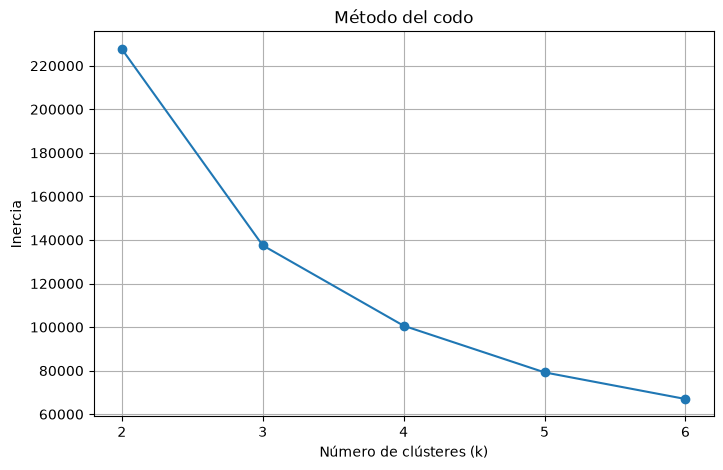

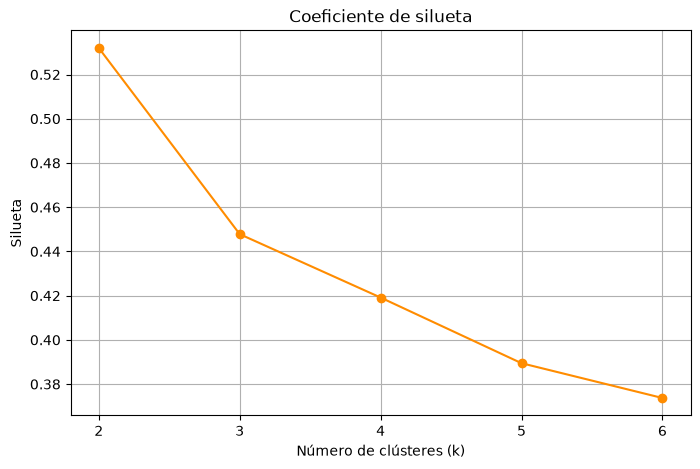

In [8]:
# Guardar las métricas de cada modelo
resultados_k = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    inercia = modelo.inertia_

    silueta = silhouette_score(
        X_escalado,
        etiquetas,
        sample_size=5000,
        random_state=42
    )

    resultados_k.append({
        "k": k,
        "Inercia": inercia,
        "Silueta": silueta
    })

# Tabla comparativa
metricas_k = pd.DataFrame(resultados_k)

print("Comparación del número de clústeres:")
display(metricas_k.round(4))

# Primera gráfica: método del codo
plt.figure(figsize=(8, 5))
plt.plot(metricas_k["k"], metricas_k["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(metricas_k["k"])
plt.grid(True)
plt.show()

# Segunda gráfica: coeficiente de silueta
plt.figure(figsize=(8, 5))
plt.plot(
    metricas_k["k"],
    metricas_k["Silueta"],
    marker="o",
    color="darkorange"
)
plt.title("Coeficiente de silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta")
plt.xticks(metricas_k["k"])
plt.grid(True)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

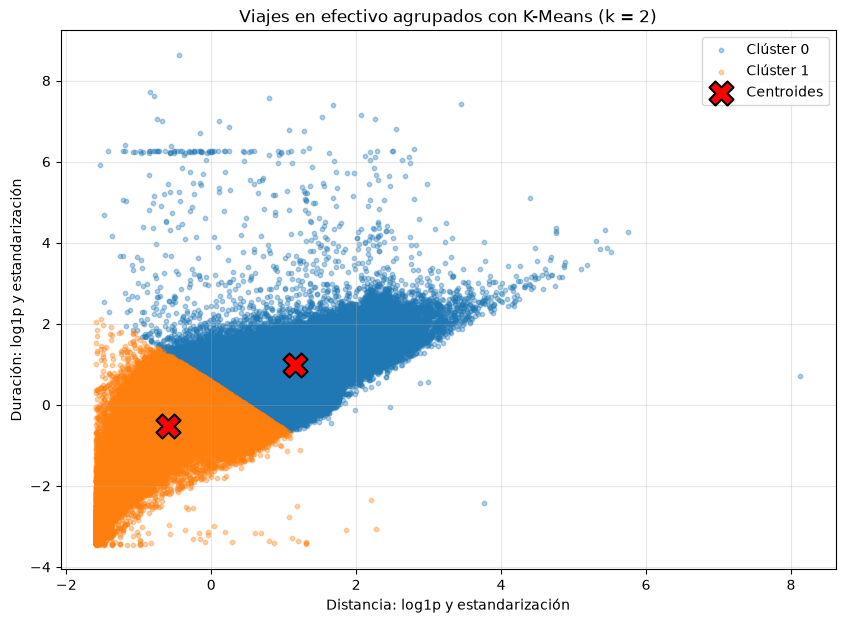

Etiquetas de los clústeres:
[0 1]

Cantidad de etiquetas:
282085

Centroides en la escala del modelo:


,trip_distance,trip_duration
0,1.150716,0.993410
1,-0.593956,-0.512761


In [9]:
k_elegido = 2
modelo_final = KMeans(
    n_clusters=k_elegido,
    random_state=42,
    n_init=10
)

etiquetas_finales = modelo_final.fit_predict(X_escalado)

# Obtener las coordenadas de los centroides
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(10, 7))

for grupo in range(k_elegido):
    puntos = X_escalado[etiquetas_finales == grupo]

    plt.scatter(
        puntos["trip_distance"],
        puntos["trip_duration"],
        s=10,
        alpha=0.35,
        label=f"Clúster {grupo}"
    )

# Dibujar los centroides en la misma escala
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=300,
    color="red",
    edgecolors="black",
    linewidths=1.5,
    label="Centroides",
    zorder=3
)

plt.title("Viajes en efectivo agrupados con K-Means (k = 2)")
plt.xlabel("Distancia: log1p y estandarización")
plt.ylabel("Duración: log1p y estandarización")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Etiquetas de los clústeres:")
print(np.unique(etiquetas_finales))

print("\nCantidad de etiquetas:")
print(len(etiquetas_finales))

print("\nCentroides en la escala del modelo:")
display(pd.DataFrame(centroides, columns=X_escalado.columns))

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [10]:
# Conservar los datos en sus unidades originales
df_resultado = df_cash.copy()

# Agregar el grupo asignado a cada viaje
df_resultado["cluster"] = etiquetas_finales

# Calcular los estadísticos de cada clúster
tabla_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "size"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_minutos=("trip_duration", "mean"),
    duracion_mediana_minutos=("trip_duration", "median")
)

print("Estadísticos por clúster en unidades originales:")
display(tabla_clusters.round(2))

print("\nTotal de viajes incluidos:")
print(tabla_clusters["cantidad_viajes"].sum())

Estadísticos por clúster en unidades originales:


,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_minutos,duracion_mediana_minutos
cluster,,,,,
0,95794,8.82,7.06,33.04,25.85
1,186291,1.28,1.13,9.52,8.95



Total de viajes incluidos:
282085


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**

Elegí k = 2 porque representa de mejor manera la silueta de los valores que s equieren evaluar (0.5320 frente a los 0.4478 de. k = 3), que aunque bien su inercia comenzó a disminuir conforme se añadían más grupos, esta misma comienza a dejar de ser tan notoria conforme se siguen analizando los datos. Por eso elegí dos grupos, porque permiten analizar de mejor manera los viajes que tienen ya sea menor o mayor distancia y duración.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

Al clúster 0 lo llamaría “Viajes de mayor distancia y duración”. Contiene 95,794 viajes, con una distancia media de 8.82 millas y una mediana de 7.06 millas. Su duración media es de 33.04 minutos y su mediana de 25.85 minutos.

Al clúster 1 lo llamaría “Viajes cortos y de menor duración”. Contiene 186,291 viajes, con una distancia media de 1.28 millas y una mediana de 1.13 millas. Su duración media es de 9.52 minutos y su mediana de 8.95 minutos.

En ambos grupos las medias superan las medianas, especialmente en el clúster 0. Esto sugiere que algunos viajes con valores altos elevan los promedios.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**

El clúster 0 presenta la mayor duración promedio, con 33.04 minutos. También tiene la mayor distancia promedio, con 8.82 millas. En comparación, el clúster 1 registra 9.52 minutos y 1.28 millas. Por lo tanto, el grupo de mayor duración promedio también corresponde al de mayor distancia promedio.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**

El grupo más numeroso es el clúster 1, con 186,291 viajes. Donde son mas notorios los recorridos cortos y de menor duración: su distancia mediana es de 1.13 millas y su duración mediana de 8.95 minutos. Sus promedios también son bajos respecto al otro grupo: 1.28 millas y 9.52 minutos.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**